# 32 — Where does an (α, β) correlation come from? (System I, N3)

The old notebooks 19, 20 and 26 chased an (α, β) "banana" (a negative correlation of the posterior) that came from the malformed controller, the fixed-horizon warm start and the old sensor noise. This notebook asks the question again under the corrected model: **the fixed PI law, the P2 warm start, N3 sensors and the production posterior.**

**Content (fixed before running; runbook §2f row g-32).** (1) The correlation implied by the Fisher information at the scenario points, with the inlet nominal and as a nuisance (notebook 08's results), against the fraction of samples at the upper valve limit. (2) The posterior correlation of α and β per scenario: the production posterior on D1 (and, for reference, the naive posterior on D0),
overall and split by saturation (more than 50% of a window's samples at Qc ≥ 395 L/min). (3) The effect of the **unmeasured inlet concentration Ci** (±1%) on the information: the FIM at Sc1, Sc4 and Sc5 with Ti and Tci exactly nominal and Ci drawn per replicate, against the nominal FIM of notebook 08 (same method: central differences h = 0.01 with common random numbers, 1,000 replicates, full covariance).
**Checks:** finite; the FIM at the nominal inlet reproduced from notebook 08's table within the sampling noise (the Ci-only run has its own replicates: |Δ CRB| of the nominal run versus notebook 08 is not tested, the Ci run is compared with it). No decision rule.


In [1]:
import os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
warnings.filterwarnings("ignore")
import importlib, ws_eval, ws_inlet, nb35_measured_inlet, nb29_ws_study, ws_phase3, ws_phase3_eval
for _m in (ws_eval, ws_inlet, nb35_measured_inlet, nb29_ws_study, ws_phase3, ws_phase3_eval):
    importlib.reload(_m)
we, wi, M, N29, P3, E = ws_eval, ws_inlet, nb35_measured_inlet, nb29_ws_study, ws_phase3, ws_phase3_eval
R = ROOT / "results"; FIGS = ROOT / "figures"; FIGS.mkdir(exist_ok=True); T0 = time.time()
fim = pd.read_csv(R / "08_N3_fim.csv"); assert np.isfinite(fim.corr_implied).all()


## 1. The correlation implied by the Fisher information (notebook 08)

corr_implied                    crb_sd_a                 \
mode         nominal (S1) nuisance (S1m) nominal (S1) nuisance (S1m)   
point                                                                  
Sc1                 0.042          0.140        0.051          0.051   
Sc2                 0.086          0.162        0.050          0.055   
Sc3                 0.090          0.166        0.025          0.026   
Sc4                 0.084          0.163        0.038          0.039   
Sc5                 0.132          0.241        0.059          0.057   
sev beta=0.4        0.085          0.175        0.059          0.062   
sev beta=0.7        0.099          0.149        0.051          0.054   

                 crb_sd_b                ratio_Iaa_Ibb                 \
mode         nominal (S1) nuisance (S1m)  nominal (S1) nuisance (S1m)   
point                                                                   
Sc1                 0.014          0.044         0.080          0.723   
Sc2                 0.016          0.043         0.096          0.611   
Sc3                 0.015          0.044         0.351          2.835   
Sc4                 0.015          0.044         0.162          1.285   
Sc5                 0.021          0.046         0.127          0.649   
sev beta=0.4        0.022          0.048         0.140          0.597   
sev beta=0.7        0.023          0.043         0.202          0.630   

             frac_Qc_ge395  
mode                        
point                       
Sc1                  0.212  
Sc2                  0.381  
Sc3                  0.182  
Sc4                  0.390  
Sc5                  0.776  
sev beta=0.4         0.899  
sev beta=0.7         0.546

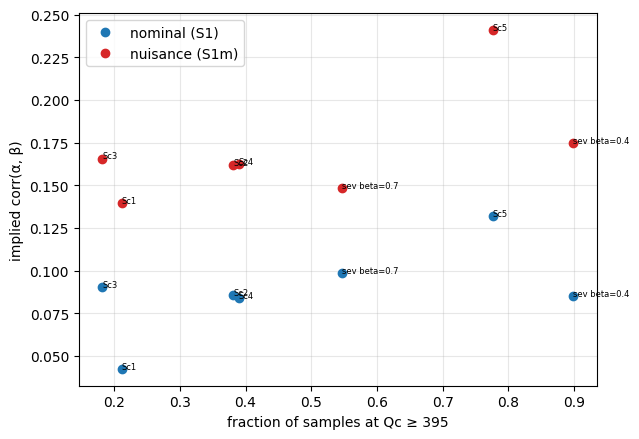

In [2]:
t = fim.pivot_table(index="point", columns="mode", values=["corr_implied", "crb_sd_a", "crb_sd_b", "ratio_Iaa_Ibb"]); sat = fim.groupby("point").frac_Qc_ge395.first()
t[("frac_Qc_ge395", "")] = sat; display(t.round(3))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for mode, c in (("nominal (S1)", "tab:blue"), ("nuisance (S1m)", "tab:red")):
    f = fim[fim["mode"] == mode]; ax.plot(f.frac_Qc_ge395, f.corr_implied, "o", color=c, label=mode)
    for _, r in f.iterrows(): ax.annotate(r.point, (r.frac_Qc_ge395, r.corr_implied), fontsize=6)
ax.set_xlabel("fraction of samples at Qc ≥ 395"); ax.set_ylabel("implied corr(α, β)"); ax.grid(alpha=.3); ax.legend(); fig.tight_layout(); fig.savefig(FIGS / "32_N3_fim_corr_vs_saturation.png", dpi=150); plt.show()


## 2. The posterior correlation of (α, β): per scenario and by saturation

In [3]:
rows = []
for lab, which, dn, seed in (("production on D1", "prod", "D1", 71), ("naive on D0", "naive", "D0", 72)):
    s, d, _ = E.draws(which, dn, 1000, seed=seed)
    c = np.array([np.corrcoef(s[i, :, 0], s[i, :, 1])[0, 1] for i in range(len(s))]); sid = d["scenario_id"]
    sat_ = (d["x"][:, :, 3] >= 395).mean(1) > 0.5
    for sc, nm in E.SCN.items():
        for grp, m in (("all", sid == sc), ("unsaturated", (sid == sc) & ~sat_), ("saturated", (sid == sc) & sat_)):
            if m.sum() >= 3: rows.append(dict(posterior=lab, scenario=nm, group=grp, n=int(m.sum()), corr_mean=float(np.nanmean(c[m])), corr_sd=float(np.nanstd(c[m]))))
pc = pd.DataFrame(rows); display(pc.pivot_table(index=["posterior", "scenario"], columns="group", values="corr_mean").round(3)); pc.to_csv(R / "32_N3_posterior_corr.csv", index=False)


group                        all  saturated  unsaturated
posterior        scenario                               
naive on D0      Sc1       0.044        NaN        0.044
                 Sc2       0.093        NaN        0.093
                 Sc3       0.046        NaN        0.046
                 Sc4       0.084        NaN        0.084
                 Sc5       0.092      0.092          NaN
                 Sc7       0.082        NaN        0.082
production on D1 Sc1       0.099      0.158        0.074
                 Sc2       0.133      0.179        0.101
                 Sc3       0.134      0.235        0.125
                 Sc4       0.143      0.214        0.110
                 Sc5       0.154      0.154        0.153
                 Sc7       0.099      0.127        0.081

## 3. The effect of the unmeasured inlet concentration Ci (Ti and Tci exactly nominal; Ci ± 1% per replicate)

In [4]:
N_REP, H = 1000, 0.01; rows = []
for pi, (name, th0) in enumerate({"Sc1": (1.0, 1.0), "Sc4": (0.85, 0.85), "Sc5": (1.0, 0.5)}.items()):
    th0 = np.array(th0, np.float32); vs = [th0, th0 + [H, 0], th0 - [H, 0], th0 + [0, H], th0 - [0, H]]
    rng = np.random.default_rng(8_500_000 + pi); nom = wi.NOMINAL.astype(np.float64)
    inl = np.tile(nom, (N_REP, 1)); inl[:, 0] = nom[0] * (1 + rng.normal(0, M.CI_REL_SD, N_REP)); inl = inl.astype(np.float32)
    arrs = [we.features(np.array(wi.simulate(np.tile(v, (N_REP, 1)), inl, M.PROTOCOL, 8_600_000 + pi, raw=True, **M.NOISE), np.float32), np.arange(1, 121) * 0.5, "S1_base_est") for v in vs]
    X0, ap, am, bp, bm = arrs; G = np.stack([(ap - am).mean(0) / (2 * H), (bp - bm).mean(0) / (2 * H)], axis=1)
    F = N29._fim(G, X0, "full"); Fi = np.linalg.inv(F)
    rows.append(dict(point=name, mode="Ci only (Ti, Tci nominal)", I_aa=F[0, 0], I_bb=F[1, 1], ratio_Iaa_Ibb=F[0, 0] / F[1, 1], corr_implied=float(-F[0, 1] / np.sqrt(F[0, 0] * F[1, 1])), crb_sd_a=float(np.sqrt(Fi[0, 0])), crb_sd_b=float(np.sqrt(Fi[1, 1]))))
ci = pd.DataFrame(rows); assert np.isfinite(ci[["crb_sd_a", "crb_sd_b"]]).all().all()
nom = fim[fim["mode"] == "nominal (S1)"].set_index("point"); nui = fim[fim["mode"] == "nuisance (S1m)"].set_index("point")
cmp_ = pd.DataFrame({"crb_b_nominal": nom.loc[ci.point, "crb_sd_b"].values, "crb_b_Ci_only": ci.crb_sd_b.values, "crb_b_all_inlet_nuisance": nui.loc[ci.point, "crb_sd_b"].values,
                     "crb_a_nominal": nom.loc[ci.point, "crb_sd_a"].values, "crb_a_Ci_only": ci.crb_sd_a.values, "crb_a_all_inlet_nuisance": nui.loc[ci.point, "crb_sd_a"].values,
                     "corr_nominal": nom.loc[ci.point, "corr_implied"].values, "corr_Ci_only": ci.corr_implied.values, "corr_all_inlet_nuisance": nui.loc[ci.point, "corr_implied"].values}, index=ci.point)
display(cmp_.round(4)); cmp_.to_csv(R / "32_N3_ci_effect.csv"); print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")


,crb_b_nominal,crb_b_Ci_only,crb_b_all_inlet_nuisance,crb_a_nominal,crb_a_Ci_only,crb_a_all_inlet_nuisance,corr_nominal,corr_Ci_only,corr_all_inlet_nuisance
point,,,,,,,,,
Sc1,0.0144,0.0158,0.0435,0.0510,0.0500,0.0512,0.0424,0.0100,0.1398
Sc4,0.0152,0.0183,0.0441,0.0379,0.0358,0.0389,0.0841,0.1541,0.1626
Sc5,0.0211,0.0272,0.0460,0.0594,0.0577,0.0571,0.1317,0.1106,0.2410


notebook wall time 1.8 min


## 6. Interpretation

**The old banana is gone, and what remains is a small positive correlation.** Under the fixed PI law, P2 and N3 sensors, the correlation of α and β is **positive and modest** in every view: implied by the Fisher information +0.04–0.13 with the inlet nominal and +0.14–0.24 with the inlet as a nuisance (notebook 08); in the production posterior on D1 the per-window posterior correlation averages +0.10 to +0.15 in Sc1–Sc5 (+0.10 in Sc7) and in the naive posterior on D0 +0.04 to +0.09. The strong negative
correlation that notebooks 19, 20 and 26 chased came from the malformed controller and the old warm start/sensor model, not from the plant.

**Saturation raises it.** In the production posterior the windows with the valve at the upper limit (more than half of the samples at Qc ≥ 395) have a higher correlation than the unsaturated windows of the same scenario: +0.16 against +0.07 in Sc1, +0.18 against +0.10 in Sc2, +0.24 against +0.13 in Sc3, +0.21 against +0.11 in Sc4 (Sc5 is saturated throughout: +0.15). The FIM agrees on the direction (Sc5, 78% saturated, has the largest implied
correlation at +0.13 nominal and +0.24 nuisance). In the naive posterior on D0, where only Sc5 saturates, the saturation effect is not visible: Sc5 (+0.09) is no larger than the unsaturated Sc2 (+0.09) and Sc4 (+0.08); it shows in the production posterior on D1 and in the FIM. This is the "positive under valve saturation" statement of the plan, in a weaker form than the plan assumed: positive everywhere, larger under saturation, never large. Why: with the valve at its limit the temperature is no longer held at the setpoint and a change of the heat-removal capacity (β) trades against
the reaction heat (α) in the jacket balance; we did not isolate this mechanism here (no controlled experiment on the balance), the numbers show only the direction and size.

**What the unmeasured inlet concentration adds.** With Ti and Tci exactly nominal and only Ci ± 1% varying, the β bound moves from 0.0144 to 0.0158 (Sc1, +10%), from 0.0152 to 0.0183 (Sc4, +20%) and from 0.0211 to 0.0272 (Sc5, +29%); the α bound is unchanged (0.050, 0.036, 0.058 against 0.051, 0.038, 0.059). The 0.044–0.046 of the full nuisance mode is therefore mostly the inlet *temperatures* and their 0.1 K measurement error; Ci alone costs β 10–30%.
Its effect on the implied correlation is not systematic (+0.010, +0.154, +0.111 against +0.042, +0.084, +0.132 for Sc1, Sc4, Sc5): within what replicate noise of a 1,000-window FIM allows we cannot say that Ci changes the correlation.

**For the paper.** (i) No α–β banana in the corrected model; the correlation is small, positive and increases with saturation. (ii) The posterior correlation (+0.10–0.15) is of the size the information bound implies (+0.14–0.24, nuisance), i.e. the posterior is not creating a correlation the data do not contain. (iii) The silent-failure sources that *do* create a large artefact correlation are the earlier ones (P1 warm start, sensor-model ladder; ledger rows from notebooks 29 and 33).

**Ledger.** Supports: the corrected-model correlation figures above; the Ci result. Does not support: a negative correlation, a large correlation under saturation, or a mechanism beyond the direction and size.